# Actividad 3A · Implementación y comparación de índices de vecinos más cercanos

**Autor:** David Segundo García
**Fecha:** 28 de septiembre de 2026

**Objetivo.** Construir y comparar índices de vecinos más cercanos aproximados (ANN) de **tres familias**:
**LSH** (funciones hash sensibles a la localidad), **cuantización vectorial** (IVF‑PQ) y **grafos de proximidad** (HNSW).
Se comparan contra una búsqueda exhaustiva exacta en exactitud (recall@10), tiempo promedio de consulta y memoria,
sobre dos colecciones del mismo origen: **10,000** y **100,000** vectores.

| Sección | Paso de la actividad |
|---|---|
| 1. Colecciones | Paso 1 |
| 2. Métrica y línea base exacta | Paso 2 |
| 3. Índices e hiperparámetros | Paso 3 |
| 4. Barrido de hiperparámetros y curvas recall vs. tiempo | Paso 4 |
| 5. Punto de operación (recall@10 ≥ 0.90) | Paso 5 |
| 6. Escalabilidad 10k → 100k | Paso 6 |
| 7. Interfaz interactiva (ipywidgets) | Paso 7 |
| 8. Conclusiones | Paso 8 (el análisis extendido está en el reporte PDF) |

In [1]:
# Configuración general del experimento
import os
# BLAS en 1 hilo ANTES de importar NumPy: la búsqueda exacta y los índices ANN se comparan en igualdad (1 núcleo)
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[v] = "1"
import io, time, zipfile, tempfile, urllib.request, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import faiss, hnswlib
from importlib.metadata import version
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown

warnings.filterwarnings("ignore")
SEED = 42
K = 10                         # recall@10
N_QUERIES = 1000               # consultas de evaluación (no pertenecen a ninguna colección)
DATA_DIR, RES_DIR, FIG_DIR = "data", "results", "figures"
for d in (DATA_DIR, RES_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# Las latencias se miden en UN solo hilo para que sean comparables entre bibliotecas
# (escenario de servicio: una consulta por petición). La construcción sí usa todos los núcleos.
N_CORES = os.cpu_count()
faiss.omp_set_num_threads(1)   # FAISS usa OpenMP propio; se sube a N_CORES solo al entrenar

# Paleta categórica fija por familia (validada para daltonismo); el marcador es codificación secundaria.
COLORS  = {"LSH": "#2a78d6", "IVF-PQ": "#eb6834", "HNSW": "#1baf7a", "Exacto": "#555555"}
MARKERS = {"LSH": "o", "IVF-PQ": "s", "HNSW": "^", "Exacto": "*"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

print(f"Python {platform.python_version()} | CPU: {platform.processor() or platform.machine()} ({N_CORES} núcleos)")
print(f"numpy {np.__version__} | faiss {faiss.__version__} | hnswlib {version('hnswlib')} | ipywidgets {widgets.__version__}")

Python 3.14.5 | CPU: arm (10 núcleos)
numpy 2.5.3 | faiss 1.15.1 | hnswlib 0.8.0 | ipywidgets 8.1.9


## 1. Colecciones de datos

**Origen:** embeddings de palabras **GloVe 6B** (Pennington, Socher y Manning, Stanford NLP, 2014), entrenados sobre
Wikipedia 2014 + Gigaword 5 (6 mil millones de tokens, vocabulario de 400 mil palabras). Se usa la versión de
**100 dimensiones** (`glove.6B.100d.txt`, dominio público, <https://nlp.stanford.edu/projects/glove/>).
Es un conjunto de referencia habitual en ANN‑Benchmarks y es “difícil” para los índices aproximados porque sus vecinos
están poco separados (baja contraste de distancias).

**Construcción de las colecciones (mismo origen, distinto tamaño):**
1. Se toman las 101,000 palabras más frecuentes del vocabulario (el archivo está ordenado por frecuencia).
2. Se apartan al azar **1,000 palabras como consultas** (no están indexadas; así ninguna consulta se encuentra a sí misma).
3. Las 100,000 restantes forman la **colección grande (100k)**; una muestra aleatoria de 10,000 de ellas forma la
   **colección pequeña (10k)**, de modo que 10k ⊂ 100k y ambas comparten distribución.
4. Todos los vectores se normalizan a norma L2 = 1 (ver justificación de la métrica en la sección 2).

La interfaz de la sección 7 permite consultar por palabra, lo que hace verificable a simple vista la calidad de los vecinos.

In [2]:
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_TXT = os.path.join(DATA_DIR, "glove.6B.100d.txt")
N_POOL, DIM = 101_000, 100

if not os.path.exists(GLOVE_TXT):   # descarga ~822 MB solo la primera vez
    zpath = os.path.join(DATA_DIR, "glove.6B.zip")
    print("Descargando GloVe 6B ..."); urllib.request.urlretrieve(GLOVE_URL, zpath)
    with zipfile.ZipFile(zpath) as z:
        z.extract("glove.6B.100d.txt", DATA_DIR)
    os.remove(zpath)

words, rows = [], []
with open(GLOVE_TXT, encoding="utf8") as f:
    for i, line in enumerate(f):
        if i >= N_POOL: break
        parts = line.rstrip().split(" ")
        words.append(parts[0]); rows.append(np.asarray(parts[1:], dtype=np.float32))
X_pool = np.vstack(rows); del rows
words = np.array(words, dtype=object)
assert X_pool.shape == (N_POOL, DIM)

# Normalización L2 -> producto interno == similitud coseno
X_pool /= np.linalg.norm(X_pool, axis=1, keepdims=True)

rng = np.random.default_rng(SEED)
perm = rng.permutation(N_POOL)
q_idx, base_idx = perm[:N_QUERIES], perm[N_QUERIES:]
base_idx_small = rng.choice(base_idx, size=10_000, replace=False)

Q = np.ascontiguousarray(X_pool[q_idx]);  q_words = words[q_idx]
COLL = {
    "10k":  {"X": np.ascontiguousarray(X_pool[base_idx_small]), "words": words[base_idx_small]},
    "100k": {"X": np.ascontiguousarray(X_pool[base_idx]),       "words": words[base_idx]},
}
WORD2VEC = {w: X_pool[i] for i, w in enumerate(words)}   # para la interfaz (incluye palabras-consulta)

doc = pd.DataFrame([
    {"Colección": name, "Origen": "GloVe 6B (Wikipedia+Gigaword), top‑101k palabras",
     "Nº vectores": c["X"].shape[0], "Dimensión": c["X"].shape[1], "Tipo": "float32, norma L2=1",
     "Tamaño en RAM (MB)": round(c["X"].nbytes / 2**20, 2),
     "Ejemplos": ", ".join(c["words"][:6])}
    for name, c in COLL.items()] + [
    {"Colección": "Consultas", "Origen": "mismo pool, excluidas de ambas colecciones",
     "Nº vectores": Q.shape[0], "Dimensión": DIM, "Tipo": "float32, norma L2=1",
     "Tamaño en RAM (MB)": round(Q.nbytes / 2**20, 2), "Ejemplos": ", ".join(q_words[:6])}])
display(doc)

,Colección,Origen,Nº vectores,Dimensión,Tipo,Tamaño en RAM (MB),Ejemplos
0,10k,"GloVe 6B (Wikipedia+Gigaword), top‑101k palabras",10000,100,"float32, norma L2=1",3.81,"4.2, barrels, shopkeepers, kwong, b.d., mize"
1,100k,"GloVe 6B (Wikipedia+Gigaword), top‑101k palabras",100000,100,"float32, norma L2=1",38.15,"frown, statistic, reimpose, demanding, swardt, ⅓"
2,Consultas,"mismo pool, excluidas de ambas colecciones",1000,100,"float32, norma L2=1",0.38,"bipartisan, perilously, arshavin, appiah, 7-15..."


## 2. Métrica de distancia y línea base exacta (fuerza bruta)

**Métrica elegida: distancia coseno**, $d(x,y) = 1 - \dfrac{x\cdot y}{\lVert x\rVert\,\lVert y\rVert}$.

*Justificación:*
- En embeddings de palabras la **dirección** codifica el significado y la norma está correlacionada con la frecuencia de la
  palabra; el coseno ignora la norma y es la métrica con la que se evalúan GloVe/word2vec (analogías, similitud).
- Con vectores normalizados, $\lVert x-y\rVert^2 = 2 - 2\,x\cdot y = 2\,d_{\cos}(x,y)$: la **distancia euclidiana y el coseno
  inducen el mismo orden de vecinos**. Esto permite usar sin pérdida índices diseñados para L2 (IVF‑PQ) o para
  producto interno (HNSW, `space='ip'`), y es la hipótesis natural del **LSH de hiperplanos aleatorios (SimHash)**,
  cuya probabilidad de colisión es $1-\theta/\pi$, función directa del ángulo.
- Aunque el coseno no cumple la desigualdad triangular, $\sqrt{2\,d_{\cos}}$ (la distancia euclidiana sobre la esfera) sí es
  una métrica, así que seguimos en un espacio métrico equivalente.

**Línea base:** búsqueda exhaustiva $O(N\cdot d)$ por consulta con NumPy (producto matriz‑vector + `argpartition`).
Se verifica contra `faiss.IndexFlatIP` y se usa como *ground truth* para calcular recall@10.

In [3]:
def brute_force_search(X, q, k=K):
    # Top-k exacto por similitud coseno (X y q normalizados). Devuelve (ids, distancias coseno).
    sims = X @ q
    top = np.argpartition(-sims, k)[:k]
    top = top[np.argsort(-sims[top])]
    return top, 1.0 - sims[top]

def brute_force_batch(X, Qm, k=K, block=250):
    # Ground truth para muchas consultas (por bloques para acotar memoria).
    out = np.empty((len(Qm), k), dtype=np.int64)
    for s in range(0, len(Qm), block):
        S = Qm[s:s+block] @ X.T
        part = np.argpartition(-S, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(S, part, 1), axis=1)
        out[s:s+block] = np.take_along_axis(part, order, 1)
    return out

GT = {name: brute_force_batch(c["X"], Q) for name, c in COLL.items()}

# Verificación cruzada con FAISS (IndexFlatIP = exacto)
for name, c in COLL.items():
    flat = faiss.IndexFlatIP(DIM); flat.add(c["X"])
    _, I = flat.search(Q, K)
    agree = np.mean([len(set(a) & set(b)) / K for a, b in zip(I, GT[name])])
    print(f"{name}: concordancia NumPy vs FAISS IndexFlatIP = {agree:.4f}")

# Ejemplo cualitativo
w = "king"
ids, dist = brute_force_search(COLL["100k"]["X"], WORD2VEC[w])
print(f"\nTop-10 exacto de '{w}' en 100k:", ", ".join(f"{COLL['100k']['words'][i]} ({d:.3f})" for i, d in zip(ids, dist)))

10k: concordancia NumPy vs FAISS IndexFlatIP = 1.0000


100k: concordancia NumPy vs FAISS IndexFlatIP = 1.0000

Top-10 exacto de 'king' en 100k: king (0.000), prince (0.232), queen (0.249), son (0.298), brother (0.301), monarch (0.302), throne (0.308), kingdom (0.319), father (0.320), emperor (0.329)


### Utilidades de medición

- **recall@10** $=\frac{1}{|Q|}\sum_q \frac{|A_q \cap G_q|}{10}$, con $A_q$ el top‑10 del índice y $G_q$ el top‑10 exacto.
- **Tiempo de consulta:** latencia por consulta individual (lotes de 1, 1 hilo), promedio y percentil 95 sobre 1,000 consultas,
  tras un calentamiento de 50 consultas. Incluye el overhead de la llamada desde Python, igual para todas las bibliotecas.
- **Memoria:** tamaño del índice **serializado** (`faiss.serialize_index`, archivo de `hnswlib`). Es una medida determinista del
  espacio que ocupa la estructura en RAM (incluye vectores originales si el índice los guarda). Se reporta también el tiempo de construcción.

In [4]:
def recall_at_k(I, gt, k=K):
    I = np.asarray(I)[:, :k]
    return float(np.mean([np.intersect1d(a, b).size / k for a, b in zip(I, gt)]))

def time_queries(search_one, Qm, warmup=50):
    # Ejecuta consultas una a una; devuelve (ids, latencia media ms, p95 ms).
    for q in Qm[:warmup]:
        search_one(q)
    res, lat = [], np.empty(len(Qm))
    for i, q in enumerate(Qm):
        t0 = time.perf_counter(); res.append(search_one(q)); lat[i] = time.perf_counter() - t0
    return np.vstack(res), lat.mean() * 1e3, np.percentile(lat, 95) * 1e3

def faiss_bytes(index):
    return faiss.serialize_index(index).size

def hnsw_bytes(p):
    with tempfile.TemporaryDirectory() as t:
        path = os.path.join(t, "h.bin"); p.save_index(path); return os.path.getsize(path)

MB = 2 ** 20
ROWS = []   # todas las mediciones del barrido

# Línea base exacta con las mismas utilidades (para compararla en las curvas)
for name, c in COLL.items():
    X = c["X"]
    I, t_mean, t_p95 = time_queries(lambda q: brute_force_search(X, q)[0], Q)
    ROWS.append(dict(coleccion=name, familia="Exacto", config="fuerza bruta (NumPy)", p1=None, p2=None,
                     recall=recall_at_k(I, GT[name]), t_ms=t_mean, p95_ms=t_p95,
                     mem_MB=X.nbytes / MB, build_s=0.0))
pd.DataFrame(ROWS)

,coleccion,familia,config,p1,p2,recall,t_ms,p95_ms,mem_MB,build_s
0,10k,Exacto,fuerza bruta (NumPy),None,None,1.0,0.080400,0.106375,3.814697,0.0
1,100k,Exacto,fuerza bruta (NumPy),None,None,1.0,1.047625,1.297925,38.146973,0.0


## 3. Índices implementados e hiperparámetros

| Familia | Implementación | Idea | Hiperparámetros barridos | Fijos |
|---|---|---|---|---|
| **LSH** | `faiss.IndexLSH` (+ `IndexRefineFlat`) | SimHash: proyección sobre `nbits` hiperplanos aleatorios (rotación aleatoria), se guarda el signo → código binario. Se buscan `k·k_factor` candidatos por distancia de Hamming y se re‑ordenan con el coseno exacto. | `nbits` ∈ {64, 128, 256, 512} (longitud del hash), `k_factor` ∈ {1, 5, 20, 50, 100} (candidatos re‑ordenados) | `rotate_data=True`, umbrales en 0 |
| **Cuantización vectorial** | `faiss.IndexIVFPQ` | IVF: k‑means con `nlist` celdas (cuantizador grueso); solo se exploran `nprobe` celdas. PQ: el residuo se divide en `M` sub‑vectores y cada uno se codifica con 1 byte (256 centroides). Distancias asimétricas (ADC). | `M` ∈ {10, 20, 50} (bytes por vector), `nprobe` ∈ {1, 2, 4, 8, 16, 32, 64, 128} | `nlist = 2√N` (200 / 632), `nbits=8`, L2 sobre vectores unitarios |
| **Grafo de proximidad** | `hnswlib` (HNSW) | Grafo jerárquico navegable de mundo pequeño; búsqueda voraz desde la capa superior con una lista dinámica de tamaño `ef`. | `M` ∈ {8, 16, 32, 48} (grado del grafo), `ef_search` ∈ {10, 20, 40, 80, 160, 320, 640} | `ef_construction=200`, `space='ip'`, semilla 100 |

**Notas de diseño.**
- `IndexLSH` de FAISS compara los códigos binarios de forma exhaustiva (con popcount, muy rápido) en lugar de usar tablas hash
  con cubetas; es LSH como **bosquejo/compresión**. Sin re‑ordenamiento (`k_factor=1`), el recall está acotado por la
  aproximación de Hamming; el re‑ordenamiento exacto necesita los vectores originales, lo que aumenta la memoria. Se reportan ambos casos.
- En IVF‑PQ, `M` controla la **memoria y el techo de exactitud** (compresión 400 B → `M` B por vector) y `nprobe` controla el **tiempo**.
- En HNSW, `M` controla **memoria y calidad del grafo**; `ef_search` es la perilla de tiempo↔recall en consulta.

In [5]:
LSH_NBITS, LSH_KF = [64, 128, 256, 512], [1, 5, 20, 50, 100]
PQ_M, PQ_NPROBE = [10, 20, 50], [1, 2, 4, 8, 16, 32, 64, 128]
HNSW_M, HNSW_EF = [8, 16, 32, 48], [10, 20, 40, 80, 160, 320, 640]
HNSW_EFC = 200

def nlist_for(n):
    return int(round(2 * np.sqrt(n)))

def build_lsh(X, nbits):
    lsh = faiss.IndexLSH(DIM, nbits, True, False)   # rotate_data=True, train_thresholds=False
    lsh.train(X)
    idx = faiss.IndexRefineFlat(lsh)                 # guarda vectores para re-ordenar
    idx.add(X)
    return idx, lsh

def build_ivfpq(X, m):
    faiss.omp_set_num_threads(N_CORES)
    nlist = nlist_for(len(X))
    quant = faiss.IndexFlatL2(DIM)
    idx = faiss.IndexIVFPQ(quant, DIM, nlist, m, 8)
    idx.cp.seed = SEED; idx.pq.cp.seed = SEED
    idx.train(X); idx.add(X)
    faiss.omp_set_num_threads(1)
    return idx

def build_hnsw(X, m):
    p = hnswlib.Index(space="ip", dim=DIM)
    p.init_index(max_elements=len(X), ef_construction=HNSW_EFC, M=m, random_seed=100)
    p.add_items(X, np.arange(len(X)), num_threads=N_CORES)
    p.set_num_threads(1)
    return p

def sweep(name):
    X, gt, rows = COLL[name]["X"], GT[name], []
    # --- LSH ---
    for nb in LSH_NBITS:
        t0 = time.perf_counter(); idx, lsh = build_lsh(X, nb); tb = time.perf_counter() - t0
        mem_full, mem_codes = faiss_bytes(idx) / MB, faiss_bytes(lsh) / MB
        for kf in LSH_KF:
            idx.k_factor = kf
            I, tm, tp = time_queries(lambda q: idx.search(q[None, :], K)[1][0], Q)
            rows.append(dict(coleccion=name, familia="LSH", config=f"nbits={nb}, k_factor={kf}", p1=nb, p2=kf,
                             recall=recall_at_k(I, gt), t_ms=tm, p95_ms=tp,
                             mem_MB=mem_codes if kf == 1 else mem_full, build_s=tb))
    # --- IVF-PQ ---
    for m in PQ_M:
        t0 = time.perf_counter(); idx = build_ivfpq(X, m); tb = time.perf_counter() - t0
        mem = faiss_bytes(idx) / MB
        for npb in PQ_NPROBE:
            idx.nprobe = npb
            I, tm, tp = time_queries(lambda q: idx.search(q[None, :], K)[1][0], Q)
            rows.append(dict(coleccion=name, familia="IVF-PQ", config=f"M={m}, nprobe={npb}", p1=m, p2=npb,
                             recall=recall_at_k(I, gt), t_ms=tm, p95_ms=tp, mem_MB=mem, build_s=tb))
    # --- HNSW ---
    for m in HNSW_M:
        t0 = time.perf_counter(); p = build_hnsw(X, m); tb = time.perf_counter() - t0
        mem = hnsw_bytes(p) / MB
        for ef in HNSW_EF:
            p.set_ef(ef)
            I, tm, tp = time_queries(lambda q: p.knn_query(q, k=K)[0][0], Q)
            rows.append(dict(coleccion=name, familia="HNSW", config=f"M={m}, ef={ef}", p1=m, p2=ef,
                             recall=recall_at_k(I, gt), t_ms=tm, p95_ms=tp, mem_MB=mem, build_s=tb))
    return rows

**Nota sobre la memoria de LSH:** con `k_factor=1` no hay re‑ordenamiento, así que se reporta solo el tamaño de los códigos
binarios (`nbits/8` bytes por vector). Con `k_factor>1` se reporta el índice completo (códigos + vectores float32 para re‑ordenar).

## 4. Barrido de hiperparámetros (ambas colecciones)

Se ejecuta el barrido completo para 10k y 100k (paso 4 y, a la vez, paso 6). En total, 20 + 24 + 28 = 72 configuraciones
por colección, cada una evaluada con 1,000 consultas.

In [6]:
t0 = time.perf_counter()
for name in COLL:
    ROWS += sweep(name)
    print(f"Barrido {name} terminado ({time.perf_counter()-t0:.0f} s acumulados)")
res = pd.DataFrame(ROWS)
res.to_csv(os.path.join(RES_DIR, "sweep_results.csv"), index=False)
print(f"{len(res)} filas guardadas en results/sweep_results.csv")

Barrido 10k terminado (8 s acumulados)


Barrido 100k terminado (40 s acumulados)
146 filas guardadas en results/sweep_results.csv


In [7]:
fmt = {"recall": "{:.3f}", "t_ms": "{:.4f}", "p95_ms": "{:.4f}", "mem_MB": "{:.2f}", "build_s": "{:.2f}"}
for name in COLL:
    display(Markdown(f"### Resultados del barrido · colección {name}"))
    for fam in ["LSH", "IVF-PQ", "HNSW"]:
        sub = res[(res.coleccion == name) & (res.familia == fam)]
        piv = sub.pivot(index="p1", columns="p2", values="recall")
        a, b = {"LSH": ("nbits", "k_factor"), "IVF-PQ": ("M", "nprobe"), "HNSW": ("M", "ef_search")}[fam]
        piv.index.name, piv.columns.name = a, b
        display(Markdown(f"**{fam}** · recall@10 ({a} × {b})"))
        display(piv.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0, vmax=1))

### Resultados del barrido · colección 10k

**LSH** · recall@10 (nbits × k_factor)

k_factor,1.000000,5.000000,20.000000,50.000000,100.000000
nbits,,,,,
64.000000,0.209,0.436,0.664,0.810,0.900
128.000000,0.380,0.699,0.898,0.960,0.987
256.000000,0.506,0.850,0.971,0.996,0.999
512.000000,0.630,0.948,0.998,1.000,1.000


**IVF-PQ** · recall@10 (M × nprobe)

nprobe,1.000000,2.000000,4.000000,8.000000,16.000000,32.000000,64.000000,128.000000
M,,,,,,,,
10.000000,0.354,0.425,0.478,0.505,0.525,0.533,0.535,0.536
20.000000,0.398,0.503,0.585,0.640,0.673,0.688,0.694,0.696
50.000000,0.425,0.556,0.681,0.779,0.845,0.883,0.899,0.904


...

k_factor,1.000000,5.000000,20.000000,50.000000,100.000000
nbits,,,,,
64.000000,0.193,0.385,0.576,0.695,0.775
128.000000,0.363,0.652,0.841,0.917,0.959
256.000000,0.490,0.821,0.952,0.985,0.994
512.000000,0.617,0.936,0.992,0.999,1.000


**IVF-PQ** · recall@10 (M × nprobe)

nprobe,1.000000,2.000000,4.000000,8.000000,16.000000,32.000000,64.000000,128.000000
M,,,,,,,,
10.000000,0.338,0.401,0.448,0.474,0.485,0.491,0.493,0.494
20.000000,0.412,0.508,0.583,0.632,0.661,0.677,0.685,0.688
50.000000,0.467,0.594,0.706,0.794,0.851,0.884,0.902,0.910


**HNSW** · recall@10 (M × ef_search)

ef_search,10.000000,20.000000,40.000000,80.000000,160.000000,320.000000,640.000000
M,,,,,,,
8.000000,0.682,0.799,0.879,0.937,0.969,0.988,0.996
16.000000,0.798,0.890,0.945,0.974,0.990,0.997,1.000
32.000000,0.854,0.930,0.971,0.991,0.998,1.000,1.000
48.000000,0.870,0.941,0.977,0.993,0.999,1.000,1.000


### Curvas de compromiso recall@10 vs. tiempo de consulta

Cada punto es una configuración; la línea une la **frontera de Pareto** de cada familia (configuraciones para las que no
existe otra más rápida con mayor recall). La estrella gris es la búsqueda exacta. La línea punteada marca el requisito
recall@10 = 0.90 de la sección 5.

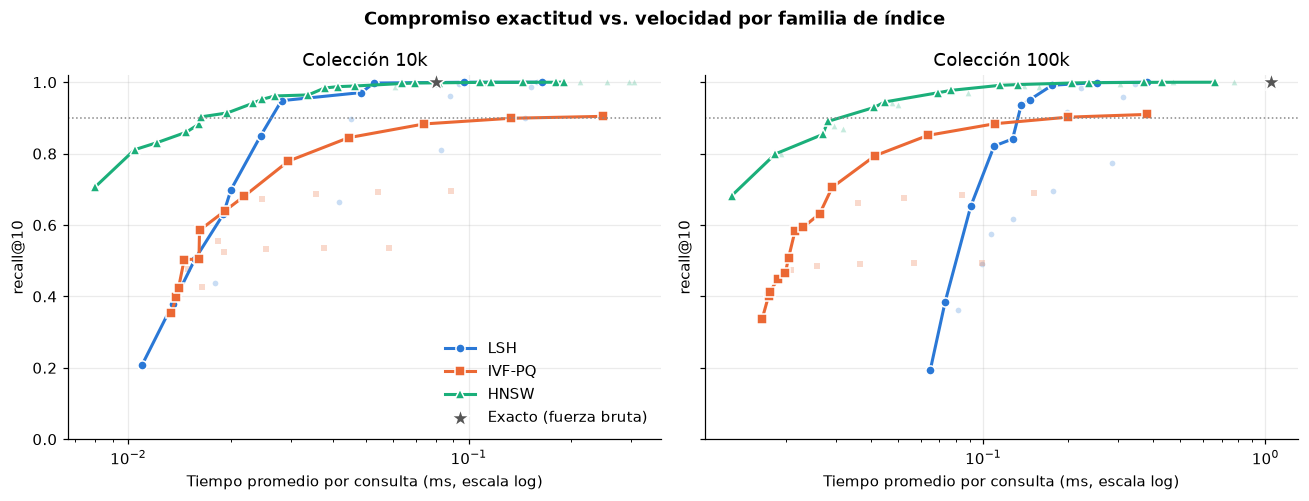

In [8]:
def pareto(df):
    # Frontera de Pareto: minimiza tiempo, maximiza recall.
    df = df.sort_values(["t_ms", "recall"], ascending=[True, False])
    keep, best = [], -1
    for i, r in df.iterrows():
        if r.recall > best:
            keep.append(i); best = r.recall
    return df.loc[keep]

def plot_tradeoff(ax, name, highlight=None, show_all=True):
    sub = res[res.coleccion == name]
    for fam in ["LSH", "IVF-PQ", "HNSW"]:
        f = sub[sub.familia == fam]
        if show_all:
            ax.scatter(f.t_ms, f.recall, s=14, color=COLORS[fam], alpha=0.25, marker=MARKERS[fam], linewidths=0)
        pf = pareto(f)
        ax.plot(pf.t_ms, pf.recall, "-", lw=2, color=COLORS[fam], marker=MARKERS[fam], ms=6,
                markeredgecolor="white", markeredgewidth=1, label=fam)
    ex = sub[sub.familia == "Exacto"].iloc[0]
    ax.scatter([ex.t_ms], [ex.recall], s=160, marker="*", color=COLORS["Exacto"], zorder=5,
               edgecolor="white", label="Exacto (fuerza bruta)")
    ax.axhline(0.90, ls=":", color="#888888", lw=1)
    if highlight is not None:
        ax.scatter([highlight[0]], [highlight[1]], s=220, facecolors="none", edgecolors="black", lw=1.8, zorder=6)
    ax.set_xscale("log"); ax.set_ylim(0, 1.02)
    ax.set_xlabel("Tiempo promedio por consulta (ms, escala log)"); ax.set_ylabel("recall@10")
    ax.set_title(f"Colección {name}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, name in zip(axes, COLL):
    plot_tradeoff(ax, name)
axes[0].legend(loc="lower right", frameon=False)
fig.suptitle("Compromiso exactitud vs. velocidad por familia de índice", fontweight="bold")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "tradeoff_recall_time.png"), dpi=180, bbox_inches="tight")
plt.show()

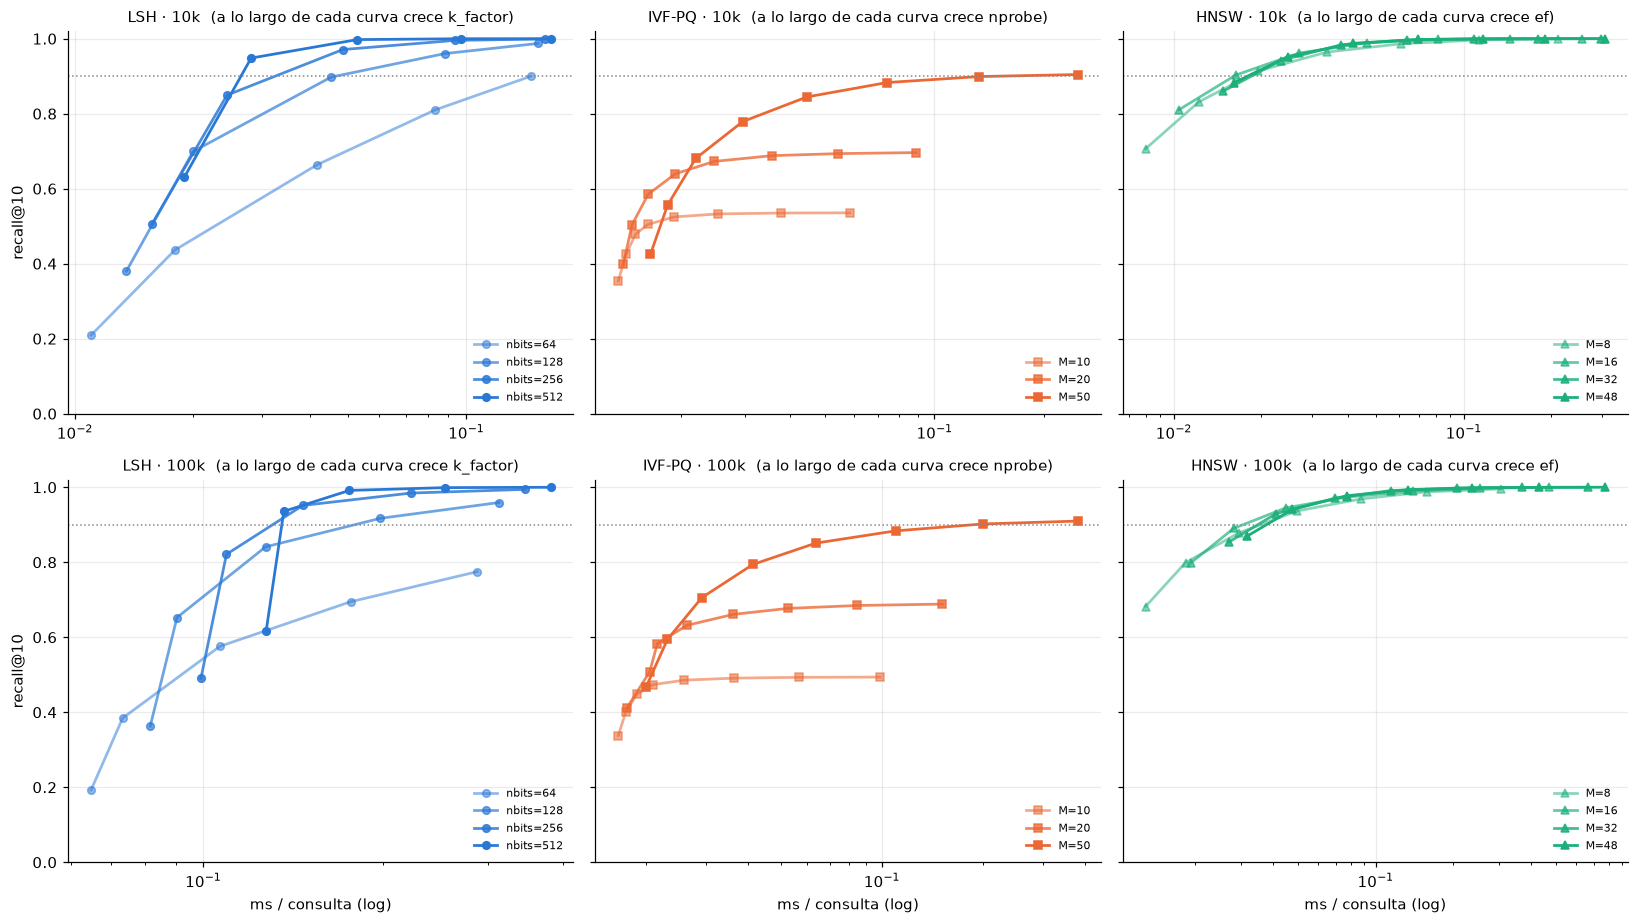

In [9]:
# Curvas completas por hiperparámetro (una línea por valor del hiperparámetro "estructural")
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharey=True)
labels = {"LSH": ("nbits", "k_factor"), "IVF-PQ": ("M", "nprobe"), "HNSW": ("M", "ef")}
for r, name in enumerate(COLL):
    for c, fam in enumerate(["LSH", "IVF-PQ", "HNSW"]):
        ax = axes[r, c]; sub = res[(res.coleccion == name) & (res.familia == fam)]
        vals = sorted(sub.p1.unique())
        for j, v in enumerate(vals):
            s = sub[sub.p1 == v].sort_values("p2")
            shade = 0.35 + 0.65 * (j + 1) / len(vals)          # misma familia, tono claro -> oscuro
            ax.plot(s.t_ms, s.recall, "-", marker=MARKERS[fam], ms=5, lw=1.8, color=COLORS[fam], alpha=shade,
                    label=f"{labels[fam][0]}={int(v)}")
        ax.axhline(0.90, ls=":", color="#888888", lw=1); ax.set_xscale("log"); ax.set_ylim(0, 1.02)
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(f"{fam} · {name}  (a lo largo de cada curva crece {labels[fam][1]})", fontsize=9.5)
        if c == 0: ax.set_ylabel("recall@10")
        if r == 1: ax.set_xlabel("ms / consulta (log)")
        ax.legend(fontsize=7.5, frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "sweeps_by_family.png"), dpi=160, bbox_inches="tight")
plt.show()

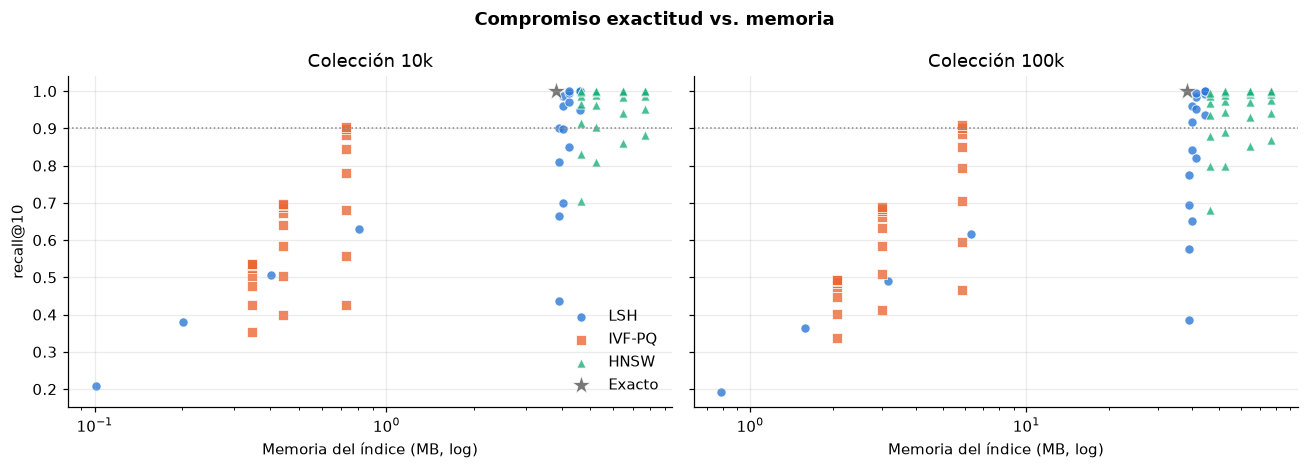

In [10]:
# Memoria vs. recall (cada punto = configuración) – muestra el costo en espacio de cada familia
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, name in zip(axes, COLL):
    sub = res[res.coleccion == name]
    for fam in ["LSH", "IVF-PQ", "HNSW", "Exacto"]:
        f = sub[sub.familia == fam]
        ax.scatter(f.mem_MB, f.recall, s=36 if fam != "Exacto" else 160, color=COLORS[fam], marker=MARKERS[fam],
                   alpha=0.8, edgecolor="white", linewidth=0.6, label=fam)
    ax.axhline(0.90, ls=":", color="#888888", lw=1); ax.set_xscale("log")
    ax.set_xlabel("Memoria del índice (MB, log)"); ax.set_title(f"Colección {name}")
axes[0].set_ylabel("recall@10"); axes[0].legend(frameon=False, loc="lower right")
fig.suptitle("Compromiso exactitud vs. memoria", fontweight="bold")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "tradeoff_recall_memory.png"), dpi=180, bbox_inches="tight")
plt.show()

## 5. Punto de operación

**Escenario definido:** buscador semántico de términos relacionados en línea (sugerencias/expansión de consultas) que atiende una
consulta por petición. **Requisito:** `recall@10 ≥ 0.90` frente a la búsqueda exacta.

**Criterio de costo:** entre las configuraciones de cada familia que cumplen el requisito se elige la de **menor tiempo promedio
de consulta**; en caso de empate práctico (±5 %) se prefiere la de menor memoria. Como criterio alternativo (escenario de memoria
limitada) también se reporta la configuración que cumple el requisito con **menor memoria**.

In [11]:
TARGET = 0.90

def pick(df, by="t_ms"):
    ok = df[df.recall >= TARGET]
    if ok.empty:
        return None
    if by == "t_ms":
        best_t = ok.t_ms.min()
        ok = ok[ok.t_ms <= best_t * 1.05].sort_values(["mem_MB", "t_ms"])
        return ok.iloc[0]
    return ok.sort_values(["mem_MB", "t_ms"]).iloc[0]

ops = []
for name in COLL:
    for fam in ["Exacto", "LSH", "IVF-PQ", "HNSW"]:
        sub = res[(res.coleccion == name) & (res.familia == fam)]
        for crit in ["t_ms", "mem_MB"]:
            r = pick(sub, crit)
            if r is None:
                ops.append(dict(coleccion=name, familia=fam, criterio=crit, config="no alcanza 0.90",
                                recall=sub.recall.max(), t_ms=np.nan, p95_ms=np.nan, mem_MB=np.nan, build_s=np.nan))
            else:
                ops.append(dict(coleccion=name, familia=fam, criterio=crit, **r[["config", "recall", "t_ms", "p95_ms",
                                                                               "mem_MB", "build_s"]].to_dict()))
ops = pd.DataFrame(ops).drop_duplicates(subset=["coleccion", "familia", "criterio"])
ops["speedup_vs_exacto"] = ops.apply(
    lambda r: ops[(ops.coleccion == r.coleccion) & (ops.familia == "Exacto")].t_ms.iloc[0] / r.t_ms, axis=1)
ops.to_csv(os.path.join(RES_DIR, "operating_points.csv"), index=False)

show = ops.rename(columns={"t_ms": "ms/consulta", "p95_ms": "p95 ms", "mem_MB": "memoria MB", "build_s": "construcción s",
                           "speedup_vs_exacto": "aceleración ×"})
display(Markdown("**Punto de operación por menor tiempo (criterio principal)**"))
display(show[show.criterio == "t_ms"].drop(columns="criterio").style.format(
    {"recall": "{:.3f}", "ms/consulta": "{:.4f}", "p95 ms": "{:.4f}", "memoria MB": "{:.2f}",
     "construcción s": "{:.2f}", "aceleración ×": "{:.1f}"}, na_rep="—").hide(axis="index"))
display(Markdown("**Punto de operación por menor memoria (escenario alternativo)**"))
display(show[show.criterio == "mem_MB"].drop(columns="criterio").style.format(
    {"recall": "{:.3f}", "ms/consulta": "{:.4f}", "p95 ms": "{:.4f}", "memoria MB": "{:.2f}",
     "construcción s": "{:.2f}", "aceleración ×": "{:.1f}"}, na_rep="—").hide(axis="index"))

**Punto de operación por menor tiempo (criterio principal)**

coleccion,familia,config,recall,ms/consulta,p95 ms,memoria MB,construcción s,aceleración ×
10k,Exacto,fuerza bruta (NumPy),1.000,0.0804,0.1064,3.81,0.00,1.0
10k,LSH,"nbits=512, k_factor=5",0.948,0.0282,0.0291,4.62,0.01,2.8
10k,IVF-PQ,"M=50, nprobe=128",0.904,0.2486,0.2537,0.73,0.77,0.3
10k,HNSW,"M=16, ef=20",0.903,0.0163,0.0205,5.24,0.19,4.9
100k,Exacto,fuerza bruta (NumPy),1.000,1.0476,1.2979,38.15,0.00,1.0
100k,LSH,"nbits=512, k_factor=5",0.936,0.1364,0.1401,44.45,0.05,7.7
100k,IVF-PQ,"M=50, nprobe=64",0.902,0.1995,0.2093,5.88,1.87,5.3
100k,HNSW,"M=32, ef=20",0.930,0.0412,0.0571,64.50,4.51,25.4


**Punto de operación por menor memoria (escenario alternativo)**

coleccion,familia,config,recall,ms/consulta,p95 ms,memoria MB,construcción s,aceleración ×
10k,Exacto,fuerza bruta (NumPy),1.000,0.0804,0.1064,3.81,0.00,1.0
10k,LSH,"nbits=128, k_factor=50",0.960,0.0882,0.0929,4.02,0.00,0.9
10k,IVF-PQ,"M=50, nprobe=128",0.904,0.2486,0.2537,0.73,0.77,0.3
10k,HNSW,"M=8, ef=40",0.914,0.0196,0.0250,4.63,0.15,4.1
100k,Exacto,fuerza bruta (NumPy),1.000,1.0476,1.2979,38.15,0.00,1.0
100k,LSH,"nbits=128, k_factor=50",0.917,0.1978,0.2065,39.72,0.01,5.3
100k,IVF-PQ,"M=50, nprobe=64",0.902,0.1995,0.2093,5.88,1.87,5.3
100k,HNSW,"M=8, ef=80",0.937,0.0497,0.0666,46.28,1.99,21.1


In [12]:
# Justificación numérica: vecindad del punto elegido (configuraciones inmediatamente más baratas fallan el requisito)
for name in COLL:
    for fam in ["LSH", "IVF-PQ", "HNSW"]:
        op = ops[(ops.coleccion == name) & (ops.familia == fam) & (ops.criterio == "t_ms")].iloc[0]
        sub = res[(res.coleccion == name) & (res.familia == fam)]
        faster = sub[sub.t_ms < op.t_ms].sort_values("recall", ascending=False).head(1)
        txt = (f"- **{name} · {fam}** → `{op.config}`: recall={op.recall:.3f}, {op.t_ms:.4f} ms, {op.mem_MB:.2f} MB, "
               f"{op.speedup_vs_exacto:.1f}× más rápido que el exacto.")
        if len(faster):
            f = faster.iloc[0]
            txt += f" La mejor configuración más rápida (`{f.config}`) solo logra recall={f.recall:.3f}."
        display(Markdown(txt))

- **10k · LSH** → `nbits=512, k_factor=5`: recall=0.948, 0.0282 ms, 4.62 MB, 2.8× más rápido que el exacto. La mejor configuración más rápida (`nbits=256, k_factor=5`) solo logra recall=0.850.

- **10k · IVF-PQ** → `M=50, nprobe=128`: recall=0.904, 0.2486 ms, 0.73 MB, 0.3× más rápido que el exacto. La mejor configuración más rápida (`M=50, nprobe=64`) solo logra recall=0.899.

- **10k · HNSW** → `M=16, ef=20`: recall=0.903, 0.0163 ms, 5.24 MB, 4.9× más rápido que el exacto. La mejor configuración más rápida (`M=48, ef=10`) solo logra recall=0.882.

- **100k · LSH** → `nbits=512, k_factor=5`: recall=0.936, 0.1364 ms, 44.45 MB, 7.7× más rápido que el exacto. La mejor configuración más rápida (`nbits=128, k_factor=20`) solo logra recall=0.841.

- **100k · IVF-PQ** → `M=50, nprobe=64`: recall=0.902, 0.1995 ms, 5.88 MB, 5.3× más rápido que el exacto. La mejor configuración más rápida (`M=50, nprobe=32`) solo logra recall=0.884.

- **100k · HNSW** → `M=32, ef=20`: recall=0.930, 0.0412 ms, 64.50 MB, 25.4× más rápido que el exacto. La mejor configuración más rápida (`M=16, ef=20`) solo logra recall=0.890.

## 6. Escalabilidad: de 10,000 a 100,000 vectores

Se comparan los puntos de operación (criterio de menor tiempo) en ambas colecciones: cómo cambian el tiempo, la memoria, el
tiempo de construcción y el hiperparámetro necesario para mantener recall@10 ≥ 0.90 cuando los datos crecen 10×.

In [13]:
a = ops[(ops.criterio == "t_ms") & (ops.coleccion == "10k")].set_index("familia")
b = ops[(ops.criterio == "t_ms") & (ops.coleccion == "100k")].set_index("familia")
scal = pd.DataFrame({
    "config 10k": a.config, "config 100k": b.config,
    "recall 10k": a.recall, "recall 100k": b.recall,
    "ms 10k": a.t_ms, "ms 100k": b.t_ms, "× tiempo": b.t_ms / a.t_ms,
    "MB 10k": a.mem_MB, "MB 100k": b.mem_MB, "× memoria": b.mem_MB / a.mem_MB,
    "aceleración vs exacto 10k": a.speedup_vs_exacto, "aceleración vs exacto 100k": b.speedup_vs_exacto,
}).loc[["Exacto", "LSH", "IVF-PQ", "HNSW"]]
scal.to_csv(os.path.join(RES_DIR, "scalability.csv"))
display(scal.style.format({c: "{:.3f}" for c in ["recall 10k", "recall 100k"]} |
                          {c: "{:.4f}" for c in ["ms 10k", "ms 100k"]} |
                          {c: "{:.2f}" for c in ["MB 10k", "MB 100k", "× tiempo", "× memoria"]} |
                          {c: "{:.1f}" for c in ["aceleración vs exacto 10k", "aceleración vs exacto 100k"]}, na_rep="—"))

# Recall con configuración FIJA (la elegida en 10k) al pasar a 100k: ¿se degrada?
fixed = []
for fam in ["LSH", "IVF-PQ", "HNSW"]:
    cfg = a.loc[fam, "config"]
    r10 = res[(res.coleccion == "10k") & (res.familia == fam) & (res.config == cfg)].iloc[0]
    r100 = res[(res.coleccion == "100k") & (res.familia == fam) & (res.config == cfg)]
    if len(r100):
        r100 = r100.iloc[0]
        fixed.append(dict(familia=fam, config=cfg, recall_10k=r10.recall, recall_100k=r100.recall,
                          ms_10k=r10.t_ms, ms_100k=r100.t_ms, x_tiempo=r100.t_ms / r10.t_ms))
display(Markdown("**Misma configuración (la óptima para 10k) aplicada a 100k**"))
display(pd.DataFrame(fixed).style.format({"recall_10k": "{:.3f}", "recall_100k": "{:.3f}", "ms_10k": "{:.4f}",
                                          "ms_100k": "{:.4f}", "x_tiempo": "{:.2f}"}).hide(axis="index"))

,config 10k,config 100k,recall 10k,recall 100k,ms 10k,ms 100k,× tiempo,MB 10k,MB 100k,× memoria,aceleración vs exacto 10k,aceleración vs exacto 100k
familia,,,,,,,,,,,,
Exacto,fuerza bruta (NumPy),fuerza bruta (NumPy),1.000,1.000,0.0804,1.0476,13.03,3.81,38.15,10.00,1.0,1.0
LSH,"nbits=512, k_factor=5","nbits=512, k_factor=5",0.948,0.936,0.0282,0.1364,4.83,4.62,44.45,9.62,2.8,7.7
IVF-PQ,"M=50, nprobe=128","M=50, nprobe=64",0.904,0.902,0.2486,0.1995,0.80,0.73,5.88,8.06,0.3,5.3
HNSW,"M=16, ef=20","M=32, ef=20",0.903,0.930,0.0163,0.0412,2.52,5.24,64.50,12.32,4.9,25.4


**Misma configuración (la óptima para 10k) aplicada a 100k**

familia,config,recall_10k,recall_100k,ms_10k,ms_100k,x_tiempo
LSH,"nbits=512, k_factor=5",0.948,0.936,0.0282,0.1364,4.83
IVF-PQ,"M=50, nprobe=128",0.904,0.910,0.2486,0.3817,1.53
HNSW,"M=16, ef=20",0.903,0.890,0.0163,0.0282,1.72


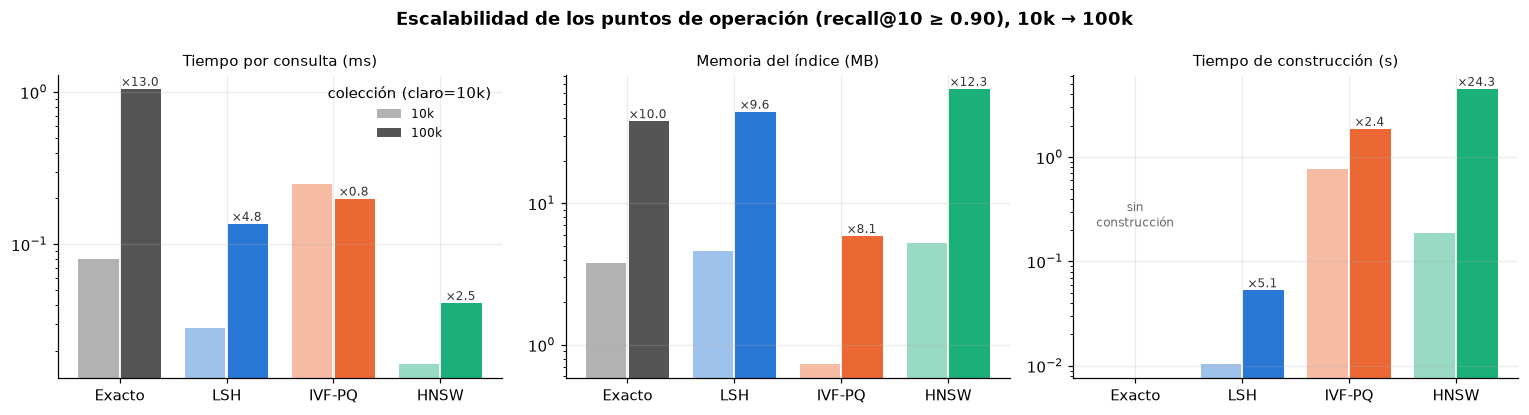

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
fams = ["Exacto", "LSH", "IVF-PQ", "HNSW"]
x = np.arange(len(fams)); w = 0.38
for ax, col, ttl in zip(axes, ["t_ms", "mem_MB", "build_s"],
                        ["Tiempo por consulta (ms)", "Memoria del índice (MB)", "Tiempo de construcción (s)"]):
    v10 = [a.loc[f, col] for f in fams]; v100 = [b.loc[f, col] for f in fams]
    ax.bar(x - w/2 - 0.01, v10, w, color=[COLORS[f] for f in fams], alpha=0.45, label="10k")
    ax.bar(x + w/2 + 0.01, v100, w, color=[COLORS[f] for f in fams], alpha=1.0, label="100k")
    for xi, (u, v) in enumerate(zip(v10, v100)):
        if u and u > 0:
            ax.annotate(f"×{v/u:.1f}", (xi + w/2, v), ha="center", va="bottom", fontsize=8, color="#333333")
        elif col == "build_s":
            ax.annotate("sin\nconstrucción", (xi, 0.5), xycoords=("data", "axes fraction"), ha="center",
                        fontsize=8, color="#666666")
    ax.set_xticks(x, fams); ax.set_title(ttl, fontsize=10); ax.set_yscale("log")
axes[0].legend(frameon=False, title="colección (claro=10k)", fontsize=8)
fig.suptitle("Escalabilidad de los puntos de operación (recall@10 ≥ 0.90), 10k → 100k", fontweight="bold")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "scalability.png"), dpi=180, bbox_inches="tight")
plt.show()

## 7. Interfaz interactiva (ipywidgets)

La interfaz recibe un **vector de consulta** de cuatro formas:
1. **Palabra**: se usa su embedding GloVe (si la palabra está indexada aparecerá como su propio vecino a distancia 0).
2. **Vector manual**: 100 números separados por comas (se normaliza automáticamente).
3. **Consulta de prueba**: una de las 1,000 palabras apartadas (no indexadas).
4. **Vector aleatorio**: dirección aleatoria en $\mathbb{R}^{100}$.

Muestra el **Top‑10** del índice seleccionado (en su punto de operación de la sección 5) con su **distancia coseno**, marca con ✓
los vecinos que coinciden con el top‑10 exacto, e informa recall y latencia de esa consulta. A la derecha grafica el
**compromiso exactitud–velocidad** de todos los índices para la colección elegida, resaltando el índice activo.

In [15]:
# Construye (una vez) cada índice en su punto de operación para cada colección
def params_of(name, fam):
    return res[(res.coleccion == name) & (res.config == ops[(ops.coleccion == name) & (ops.familia == fam) &
               (ops.criterio == "t_ms")].config.iloc[0]) & (res.familia == fam)].iloc[0]

SERVING = {}
for name, c in COLL.items():
    X = c["X"]; S = {}
    r = params_of(name, "LSH");    idx, _ = build_lsh(X, int(r.p1)); idx.k_factor = int(r.p2)
    S["LSH"] = (lambda q, idx=idx: idx.search(q[None, :], K)[1][0], r)
    r = params_of(name, "IVF-PQ"); ivf = build_ivfpq(X, int(r.p1)); ivf.nprobe = int(r.p2)
    S["IVF-PQ"] = (lambda q, ivf=ivf: ivf.search(q[None, :], K)[1][0], r)
    r = params_of(name, "HNSW");   h = build_hnsw(X, int(r.p1)); h.set_ef(int(r.p2))
    S["HNSW"] = (lambda q, h=h: h.knn_query(q, k=K)[0][0], r)
    S["Exacto"] = (lambda q, X=X: brute_force_search(X, q)[0], res[(res.coleccion == name) & (res.familia == "Exacto")].iloc[0])
    SERVING[name] = S

def parse_query(mode, text, test_i):
    # Convierte la entrada del usuario en un vector unitario de 100-d.
    if mode == "Palabra":
        w = text.strip().lower()
        if w not in WORD2VEC:
            raise ValueError(f"'{w}' no está entre las 101k palabras cargadas.")
        v, label = WORD2VEC[w], f"palabra «{w}»"
    elif mode == "Vector manual":
        v = np.array([float(t) for t in text.replace("\n", ",").split(",") if t.strip()], dtype=np.float32)
        if v.size != DIM:
            raise ValueError(f"El vector debe tener {DIM} componentes (recibí {v.size}).")
        label = "vector manual"
    elif mode == "Consulta de prueba":
        v, label = Q[test_i], f"consulta de prueba #{test_i} «{q_words[test_i]}» (no indexada)"
    else:
        v, label = np.random.default_rng().standard_normal(DIM).astype(np.float32), "vector aleatorio"
    n = np.linalg.norm(v)
    if n == 0:
        raise ValueError("El vector no puede ser cero.")
    return (v / n).astype(np.float32), label

def run_query(v, coll, fam):
    # Top-10 del índice + top-10 exacto para marcar aciertos. Devuelve DataFrame, recall y latencia (ms).
    X, wds = COLL[coll]["X"], COLL[coll]["words"]
    fn, _ = SERVING[coll][fam]
    fn(v)                                            # calentamiento
    t0 = time.perf_counter(); ids = np.asarray(fn(v))[:K]; lat = (time.perf_counter() - t0) * 1e3
    ids = ids[ids >= 0]
    exact_ids, _ = brute_force_search(X, v)
    d = 1.0 - X[ids] @ v                             # distancia coseno real de cada vecino devuelto
    order = np.argsort(d); ids, d = ids[order], d[order]
    df = pd.DataFrame({"#": np.arange(1, len(ids) + 1), "id": ids, "palabra": wds[ids],
                       "distancia coseno": np.round(d, 4),
                       "¿en top-10 exacto?": ["✓" if i in set(exact_ids) else "✗" for i in ids]})
    return df, np.intersect1d(ids, exact_ids).size / K, lat

w_mode = widgets.ToggleButtons(options=["Palabra", "Vector manual", "Consulta de prueba", "Vector aleatorio"],
                               value="Palabra", description="Entrada:", style={"button_width": "130px"})
w_text = widgets.Textarea(value="king", placeholder="palabra o 100 números separados por coma",
                          layout=widgets.Layout(width="420px", height="60px"), description="Consulta:")
w_test = widgets.IntSlider(value=0, min=0, max=N_QUERIES - 1, description="# prueba:", continuous_update=False)
w_coll = widgets.Dropdown(options=list(COLL), value="100k", description="Colección:")
w_fam  = widgets.Dropdown(options=["HNSW", "IVF-PQ", "LSH", "Exacto"], value="HNSW", description="Índice:")
w_btn  = widgets.Button(description="Buscar Top-10", button_style="primary", icon="search")
w_out_tab, w_out_plot = widgets.Output(), widgets.Output()

def render(*_):
    w_out_tab.clear_output(); w_out_plot.clear_output()
    with w_out_tab:
        try:
            v, label = parse_query(w_mode.value, w_text.value, w_test.value)
        except ValueError as e:
            display(HTML(f"<b style='color:#b00020'>Error:</b> {e}")); return
        df, rec, lat = run_query(v, w_coll.value, w_fam.value)
        cfg = SERVING[w_coll.value][w_fam.value][1]
        display(HTML(f"<b>{label}</b> · colección <b>{w_coll.value}</b> · índice <b>{w_fam.value}</b> "
                     f"(<code>{cfg.config}</code>)<br>recall@10 de esta consulta: <b>{rec:.1f}</b> · "
                     f"latencia: <b>{lat:.3f} ms</b> · recall medio del índice: {cfg.recall:.3f}"))
        display(df.style.hide(axis="index"))
    with w_out_plot:
        fig, ax = plt.subplots(figsize=(6.2, 4.3))
        cfg = SERVING[w_coll.value][w_fam.value][1]
        plot_tradeoff(ax, w_coll.value, highlight=(cfg.t_ms, cfg.recall), show_all=False)
        for fam in ["LSH", "IVF-PQ", "HNSW"]:
            o = SERVING[w_coll.value][fam][1]
            ax.annotate(f"{fam}: {o.config}", (o.t_ms, o.recall), fontsize=7, xytext=(5, -12),
                        textcoords="offset points", color="#333333")
        ax.legend(frameon=False, loc="lower right", fontsize=8)
        ax.set_title(f"Recall vs. tiempo · {w_coll.value} (círculo = índice activo)", fontsize=10)
        plt.tight_layout(); plt.show()

def on_mode(change):
    w_text.layout.display = "" if change.new in ("Palabra", "Vector manual") else "none"
    w_test.layout.display = "" if change.new == "Consulta de prueba" else "none"
    if change.new == "Vector manual":
        w_text.value = ", ".join(f"{x:.4f}" for x in WORD2VEC["computer"])
    elif change.new == "Palabra":
        w_text.value = "king"

w_mode.observe(on_mode, names="value"); w_test.layout.display = "none"
w_btn.on_click(render)
for wdg in (w_coll, w_fam):
    wdg.observe(render, names="value")

ui = widgets.VBox([w_mode, widgets.HBox([w_text, w_test]), widgets.HBox([w_coll, w_fam, w_btn]),
                   widgets.HBox([w_out_tab, w_out_plot])])
display(ui)
render()

**Salida estática de ejemplo** (visible aunque el visor no ejecute widgets): la misma función que usa la interfaz, aplicada a
dos consultas en la colección de 100k con los tres índices aproximados y el exacto.

In [16]:
for text, mode, ti in [("king", "Palabra", 0), (None, "Consulta de prueba", 7)]:
    v, label = parse_query(mode, text or "", ti)
    display(Markdown(f"#### {label} · colección 100k"))
    tables = []
    for fam in ["Exacto", "HNSW", "IVF-PQ", "LSH"]:
        df, rec, lat = run_query(v, "100k", fam)
        t = df[["palabra", "distancia coseno", "¿en top-10 exacto?"]].copy()
        t.columns = pd.MultiIndex.from_product([[f"{fam} (recall {rec:.1f}, {lat:.3f} ms)"], t.columns])
        tables.append(t.reset_index(drop=True))
    display(pd.concat(tables, axis=1).style.hide(axis="index"))

#### palabra «king» · colección 100k

#### consulta de prueba #7 «danish» (no indexada) · colección 100k

## 8. Conclusiones

Las conclusiones numéricas se generan a partir de los resultados medidos (celda siguiente). El análisis extendido y la
recomendación para producción se presentan en el reporte PDF adjunto.

In [17]:
op10  = ops[(ops.criterio == "t_ms") & (ops.coleccion == "10k")].set_index("familia")
op100 = ops[(ops.criterio == "t_ms") & (ops.coleccion == "100k")].set_index("familia")
opm   = ops[(ops.criterio == "mem_MB") & (ops.coleccion == "100k")].set_index("familia")
best_fast = op100.drop("Exacto").t_ms.idxmin()
best_mem  = opm.drop("Exacto").mem_MB.idxmin()
lines = [f"- Requisito: recall@10 ≥ {TARGET}. En **100k** el índice más rápido que lo cumple es **{best_fast}** "
         f"(`{op100.loc[best_fast,'config']}`): {op100.loc[best_fast,'t_ms']:.4f} ms/consulta, "
         f"{op100.loc[best_fast,'speedup_vs_exacto']:.0f}× más rápido que la fuerza bruta ({op100.loc['Exacto','t_ms']:.3f} ms).",
         f"- El índice que cumple el requisito con **menos memoria** en 100k es **{best_mem}** "
         f"(`{opm.loc[best_mem,'config']}`): {opm.loc[best_mem,'mem_MB']:.2f} MB vs. "
         f"{op100.loc['Exacto','mem_MB']:.2f} MB de los vectores crudos."]
for fam in ["Exacto", "LSH", "IVF-PQ", "HNSW"]:
    lines.append(f"- **{fam}**: al crecer 10× los datos, el tiempo del punto de operación cambia "
                 f"×{op100.loc[fam,'t_ms']/op10.loc[fam,'t_ms']:.2f} y la memoria ×{op100.loc[fam,'mem_MB']/op10.loc[fam,'mem_MB']:.2f} "
                 f"(`{op10.loc[fam,'config']}` → `{op100.loc[fam,'config']}`).")
display(Markdown("\n".join(lines)))

- Requisito: recall@10 ≥ 0.9. En **100k** el índice más rápido que lo cumple es **HNSW** (`M=32, ef=20`): 0.0412 ms/consulta, 25× más rápido que la fuerza bruta (1.048 ms).
- El índice que cumple el requisito con **menos memoria** en 100k es **IVF-PQ** (`M=50, nprobe=64`): 5.88 MB vs. 38.15 MB de los vectores crudos.
- **Exacto**: al crecer 10× los datos, el tiempo del punto de operación cambia ×13.03 y la memoria ×10.00 (`fuerza bruta (NumPy)` → `fuerza bruta (NumPy)`).
- **LSH**: al crecer 10× los datos, el tiempo del punto de operación cambia ×4.83 y la memoria ×9.62 (`nbits=512, k_factor=5` → `nbits=512, k_factor=5`).
- **IVF-PQ**: al crecer 10× los datos, el tiempo del punto de operación cambia ×0.80 y la memoria ×8.06 (`M=50, nprobe=128` → `M=50, nprobe=64`).
- **HNSW**: al crecer 10× los datos, el tiempo del punto de operación cambia ×2.52 y la memoria ×12.32 (`M=16, ef=20` → `M=32, ef=20`).